Import libraries

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from sklearn.datasets import make_moons # Using moons to show off the 'bending' boundary


Create the moon dataset

In [2]:
X, y = make_moons(n_samples=1500, noise=0.1, random_state=42)
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0) # Standardize
y = y.reshape(-1, 1)

Show plot

(-3.0, 3.0)

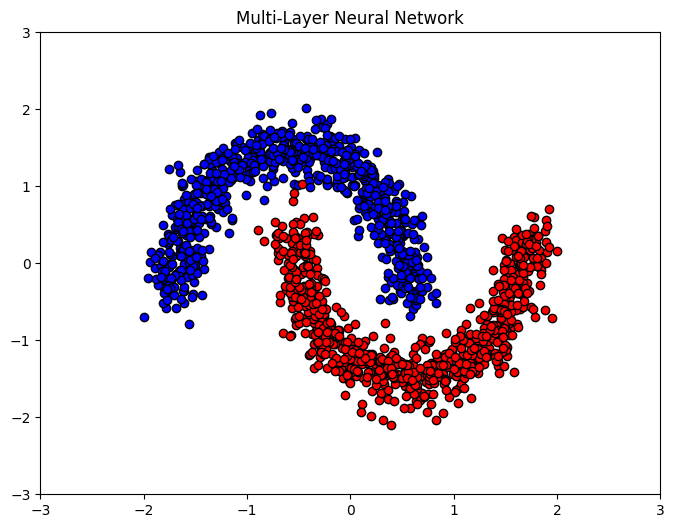

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(X[y.flatten()==0, 0], X[y.flatten()==0, 1], c='blue', edgecolors='k')
ax.scatter(X[y.flatten()==1, 0], X[y.flatten()==1, 1], c='red', edgecolors='k')
    
ax.set_title(f"Multi-Layer Neural Network")
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

Create functions<br>
function that randomize weights and biases<br>
activation function(ReLU)<br>
function for output(0, 1), choosing sigmoid for it<br>
a cost function (BCR)<br>
Forward pass(no need for a function?)<br>
Backward pass function<br>
<p style="color:blue">dz is the derivative of the loss with respect to the pre-activation output of the layer<br>
    dW is the derivative of the loss with respect to the weights of the layer<br>
    db is the derivative of the loss with respect to the biases of the layer<br>
    the goal is to compute dW and db for each layer to update the weights and biases during training<br></p>


In [ ]:
def random_layer(input_dim, output_dim):
    return np.random.randn(input_dim, output_dim) * np.sqrt(2.0 / input_dim)


def initwb(input_dim, hidden_dim, output_dim):
    W = [random_layer(input_dim, hidden_dim[0])]
    for i in range(1, len(hidden_dim)):
        W.append(random_layer(hidden_dim[i-1], hidden_dim[i]))
    W.append(random_layer(hidden_dim[-1], output_dim))

    b = [np.zeros((1, dim)) for dim in hidden_dim + [output_dim]] 

    return W, b

def ReLU(Z):
    return np.maximum(0, Z)

def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))

def binary_cross_entropy_loss(y_true, y_pred):
    m = y_true.shape[0]
    # Clip predictions to avoid log(0)
    y_pred_clipped = np.clip(y_pred, 1e-15, 1 - 1e-15)
    loss = -np.mean(y_true * np.log(y_pred_clipped) + (1 - y_true) * np.log(1 - y_pred_clipped))
    return loss

def forward_pass(X, W, b):
    """Performs a forward pass through all layers"""
    activations = [X]
    for l in range(len(W) - 1):
        Z = np.dot(activations[-1], W[l]) + b[l]
        A = ReLU(Z)
        activations.append(A)
    
    # Output layer
    Z = np.dot(activations[-1], W[-1]) + b[-1]
    A = sigmoid(Z)
    activations.append(A)
    
    return activations

def backward_propagation(y, W, b, activations):

    # m is the number of training examples
    m = len(y)
    dW = [None] * len(W)
    db = [None] * len(b)
    # derivative of BCR and sigmoid combined simplifies to (A - y) where A is the output of the sigmoid
    dz = activations[-1] - y

    for i in range(len(W) - 1, -1, -1):
        # derivative of dW, which is dz * A_prev (activations[i])
        # derivative of db, which is just the sum of dz across samples and normalized by m
        dW[i] = np.dot(activations[i].T, dz) / m
        db[i] = np.sum(dz, axis=0, keepdims=True) / m
        
        if i > 0:  # No need to backpropagate beyond input layer
            da = np.dot(dz, W[i].T)
            dz = da * (activations[i] > 0)  # ReLU derivative
        
    return dW, db
    #dW and db includes all gradients for each layer, which will be used to update weights and biases in the training loop.

def update_parameters(W, b, dW, db, lr):
    for i in range(len(W)):
        W[i] -= lr * dW[i]
        b[i] -= lr * db[i]

def calculate_accuracy(y_true, y_pred):
    # Convert probabilities to 0 or 1
    predictions = (y_pred >= 0.5).astype(int)
    # Compare with true labels and take the average
    accuracy = np.mean(predictions == y_true)
    return accuracy * 100  # Return as a percentage

First initialize and set up the network<br>
Forward pass<br>
backward pass<br>
Then, every time it has done an iteration, give out the cost value? Probably after backward pass
update the weights after backward pass dW db<br>

In [ ]:
input_dim = 2
hidden_dim = [10]
output_dim = 1
lr = 0.1
batch_size = 64
W, b = initwb(input_dim, hidden_dim, output_dim)
# set up the grid for decision boundary visualization
fig, ax = plt.subplots(figsize=(8, 6))
xx, yy = np.meshgrid(np.linspace(0, 10, 100), np.linspace(0, 10, 100))
grid = np.c_[xx.ravel(), yy.ravel()]

# the function used in animation
def train(epochs):
    global W, b

    indices = np.random.choice(len(X), batch_size, replace=False)
    X_batch = X[indices]
    y_batch = y[indices]
    ax.clear()

    activations = forward_pass(X_batch, W, b)
    loss = binary_cross_entropy_loss(y_batch, activations[-1])
    dW, db = backward_propagation(y_batch, W, b, activations)
    update_parameters(W, b, dW, db, lr)

    # Visualize decision boundary
    Z = forward_pass(grid, W, b)[-1].reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=50, cmap='RdBu', alpha=0.6)
    ax.scatter(X[y.flatten()==0, 0], X[y.flatten()==0, 1], c='blue', edgecolors='k')
    ax.scatter(X[y.flatten()==1, 0], X[y.flatten()==1, 1], c='red', edgecolors='k')
    ax.set_title(f"Epoch: {epochs+1}, Loss: {loss:.4f}, Accuracy: {calculate_accuracy(y_batch, activations[-1]):.2f}%")
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    



In [ ]:
ani = FuncAnimation(fig, train, frames=200, repeat=False)

plt.show()
"""
If widget doesn't work, use this for a rougher animation
from IPython.display import HTML
HTML(ani.to_jshtml())
"""

I'm using numpy, so I don't need to program the things like within one layer, each node multiplying the weight things in a for loop, but just single line of code to finish that, minimizing the things need do be done<br>
well, maybe I could program out the same function to do the same thing?